# Pretrained CNN for Birdsong Classification

This notebook implements a **pretrained convolutional neural network** for classifying bird species from spectrogram images.

The data preprocessing (conversion from `.wav` files to mel spectrograms and splitting into train/validation/test sets) is done in the separate notebook **`bird_CNN.ipynb`**. Here we focus on:

- loading the preprocessed spectrogram data
- building a pretrained CNN based on EfficientNetB0
- training the classification head
- evaluating the model and comparing it to the custom CNN approach


In [2]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix


## 1. Data loading

The preprocessed input data is imported from `bird_CNN.ipynb`:

- Inputs: RGB mel spectrograms of size **128 × 128 × 3**
- Target: bird species label (5 classes)
- Splits:
  - `X_train`, `y_train`
  - `X_val`, `y_val`
  - `X_test`, `y_test`

This ensures that the pretrained model uses exactly the same data as the custom CNN, which makes the later comparison fair.


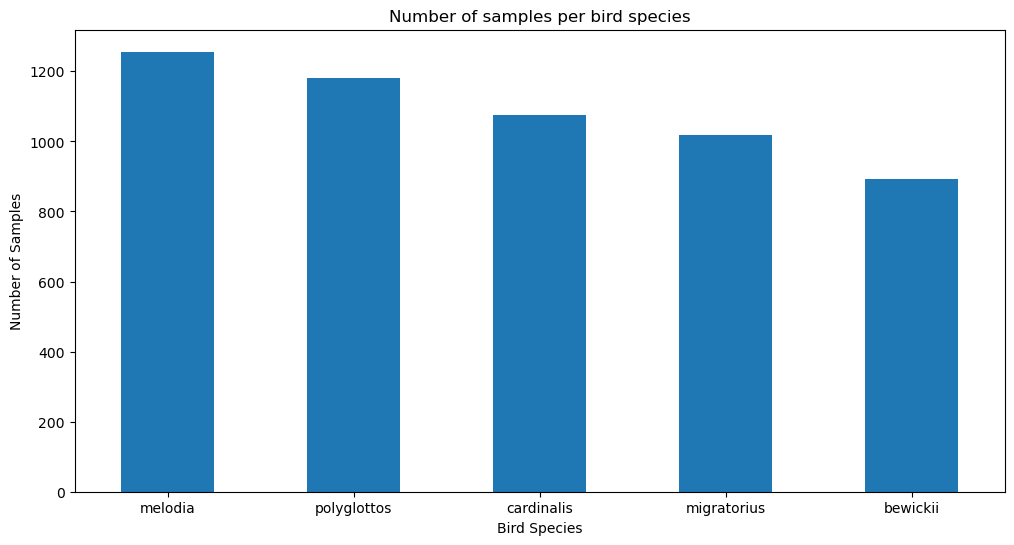

Total audio files found: 9107


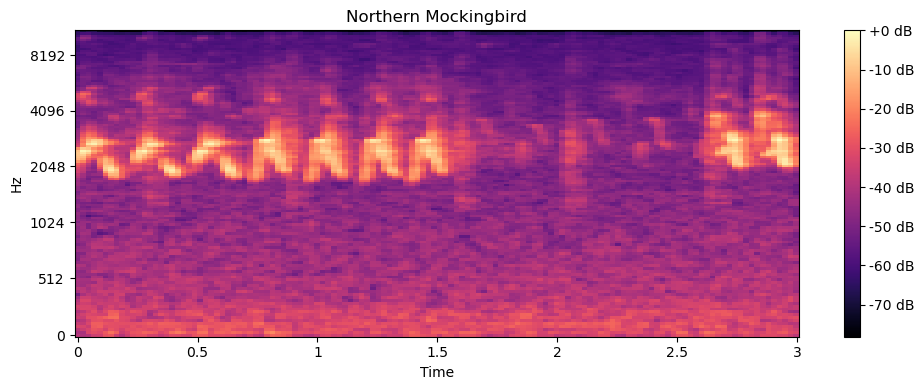

(128, 128, 3)
(4500, 128, 128, 3) (4500,)
(500, 128, 128, 3) (500,)
(422, 128, 128, 3) (422,)
Train: (4500, 128, 128, 3) (4500,)
Val:   (500, 128, 128, 3) (500,)
Test:  (422, 128, 128, 3) (422,)


In [4]:
import import_ipynb

from bird_CNN import (
    X_train, X_val, X_test,
    y_train, y_val, y_test
)

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape,   y_val.shape)
print("Test: ", X_test.shape,  y_test.shape)



In [3]:
X_train = np.load("./data/processed/X_train.npy")
y_train = np.load("./data/processed/y_train.npy")

X_val = np.load("./data/processed/X_val.npy")
y_val = np.load("./data/processed/y_val.npy")

X_test = np.load("./data/processed/X_test.npy")
y_test = np.load("./data/processed/y_test.npy")

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(4500, 128, 128, 3) (4500,)
(500, 128, 128, 3) (500,)
(422, 128, 128, 3) (422,)


## 2. Pretrained model architecture

I used **EfficientNetB0** pretrained on ImageNet as a feature extractor:

- `include_top=False`, so the original ImageNet classification head is removed
- all convolutional layers in EfficientNetB0 are **frozen** (`trainable = False`)
- inputs are normalized with `efficientnet.preprocess_input`

A small custom classification head is added on top:

- GlobalAveragePooling2D
- Dropout (0.4) for regularization
- Dense layer with 128 units and ReLU activation
- Dropout (0.3)
- Output Dense layer with `num_classes` units and softmax activation

This head is the only part that is trained on the birdsong spectrogram data.


In [4]:
input_shape = X_train.shape[1:]
num_classes = len(np.unique(y_train))

base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=input_shape
)

base_model.trainable = False

inputs = keras.Input(shape=input_shape)
x = keras.applications.efficientnet.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = keras.Model(inputs, outputs, name="bird_pretrained_cnn")
model.summary()

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=20,
    callbacks=[early_stop]
)

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print("Test accuracy:", test_acc)
print("Test loss:", test_loss)

2025-12-11 19:16:00.578628: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "bird_pretrained_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,184 (16.08 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 35s 197ms/step - accuracy: 0.2113 - loss: 1.6453 - val_accuracy: 0.2760 - val_loss: 1.6040
Epoch 2/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 23s 163ms/step - accuracy: 0.2111 - loss: 1.6206 - val_accuracy: 0.2320 - val_loss: 1.6037
Epoch 3/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 27s 192ms/step - accuracy: 0.2162 - loss: 1.6168 - val_accuracy: 0.2320 - val_loss: 1.6022
Epoch 4/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 24s 168ms/step - accuracy: 0.2158 - loss: 1.6129 - val_accuracy: 0.2320 - val_loss: 1.6035
Epoch 5/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 26s 181ms/step - accuracy: 0.2264 - loss: 1.6062 - val_accuracy: 0.2320 - val_loss: 1.6033
Epoch 6/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 25s 174ms/step - accuracy: 0.2258 - loss: 1.6095 - val_accuracy: 0.2320 - val_loss: 1.6044
Test accuracy: 0.22985781729221344
Test loss: 1.600873351097107


## 2.1 Base Model Evaluation

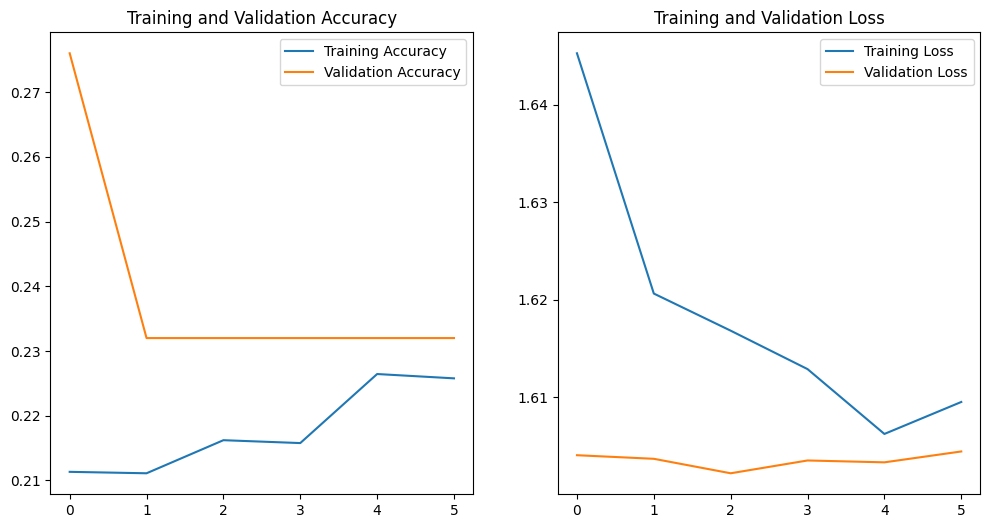

In [20]:
val_accuracy = history.history['val_accuracy']
val_loss = history.history['val_loss']
train_accuracy = history.history['accuracy']
train_loss = history.history['loss']

epochs = range(len(train_accuracy))

# Plot training  and validation accuracy
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs, train_accuracy, label='Training Accuracy')
plt.plot(epochs, val_accuracy, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(epochs, train_loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step


<Figure size 700x600 with 0 Axes>

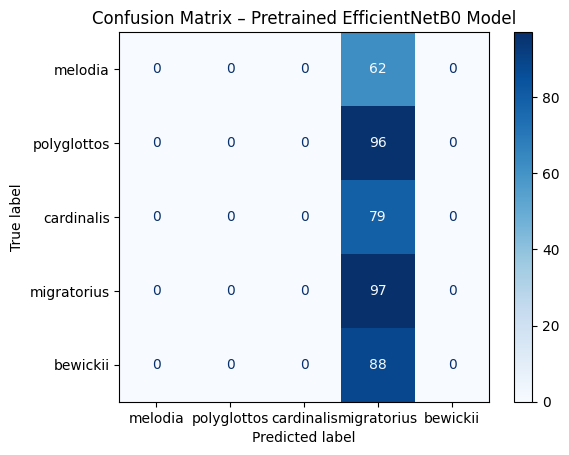

In [10]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Load test data (already saved earlier)
X_test = np.load("./data/processed/X_test.npy")
y_test = np.load("./data/processed/y_test.npy")

# 2. Predict classes
y_pred_prob = model.predict(X_test)
y_pred_classes = np.argmax(y_pred_prob, axis=1)

# 3. Build confusion matrix
cm = confusion_matrix(y_test, y_pred_classes)

# 4. Optional – class names (species order from factorize)
class_names = ["melodia", "polyglottos", "cardinalis", "migratorius", "bewickii"]

# 5. Display confusion matrix
plt.figure(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format='d')
plt.title("Confusion Matrix – Pretrained EfficientNetB0 Model")
plt.show()

## 3. Fine-Tuning the Pretrained Model (Unfreezing Some Layers)

In the initial experiment, the EfficientNetB0 backbone was fully frozen. As seen in the learning curves and confusion matrix for that version, the model failed to learn meaningful spectrogram features and collapsed into predicting a single class

To explore whether partial adaptation of the backbone helps, we unfreeze the last ~30 layers. These correspond to the deeper blocks of EfficientNet (block6d, block7a, and the top layers), which typically capture higher-level patterns. The goal is to allow the model to adjust its high-level filters to spectrogram-specific structures without retraining the entire network.

In [14]:
UNFREEZE_FROM = -30

for layer in base_model.layers[UNFREEZE_FROM:]:
    layer.trainable = True

print("Trainable layers after unfreezing:")
for i, layer in enumerate(base_model.layers):
    if layer.trainable:
        print(f"{i:3d} | {layer.name}")

Trainable layers after unfreezing:
208 | block6d_expand_bn
209 | block6d_expand_activation
210 | block6d_dwconv
211 | block6d_bn
212 | block6d_activation
213 | block6d_se_squeeze
214 | block6d_se_reshape
215 | block6d_se_reduce
216 | block6d_se_expand
217 | block6d_se_excite
218 | block6d_project_conv
219 | block6d_project_bn
220 | block6d_drop
221 | block6d_add
222 | block7a_expand_conv
223 | block7a_expand_bn
224 | block7a_expand_activation
225 | block7a_dwconv
226 | block7a_bn
227 | block7a_activation
228 | block7a_se_squeeze
229 | block7a_se_reshape
230 | block7a_se_reduce
231 | block7a_se_expand
232 | block7a_se_excite
233 | block7a_project_conv
234 | block7a_project_bn
235 | top_conv
236 | top_bn
237 | top_activation


In [16]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [17]:
fine_tune_early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

In [18]:
history_finetune = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=15,
    callbacks=[fine_tune_early_stop]
)

Epoch 1/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 42s 202ms/step - accuracy: 0.2033 - loss: 1.7021 - val_accuracy: 0.2320 - val_loss: 1.6040
Epoch 2/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 27s 191ms/step - accuracy: 0.2096 - loss: 1.6729 - val_accuracy: 0.1960 - val_loss: 1.6119
Epoch 3/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 27s 193ms/step - accuracy: 0.2091 - loss: 1.6632 - val_accuracy: 0.2200 - val_loss: 1.6087
Epoch 4/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 27s 192ms/step - accuracy: 0.2111 - loss: 1.6395 - val_accuracy: 0.2200 - val_loss: 1.6023
Epoch 5/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 28s 200ms/step - accuracy: 0.2133 - loss: 1.6336 - val_accuracy: 0.2400 - val_loss: 1.5962
Epoch 6/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 29s 204ms/step - accuracy: 0.2131 - loss: 1.6352 - val_accuracy: 0.2420 - val_loss: 1.5946
Epoch 7/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 29s 205ms/step - accuracy: 0.2249 - loss: 1.6310 - val_accuracy: 0.2520 - val_loss: 1.5942
Epoch 8/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 29s 203ms/step - accuracy: 0.2229 - loss: 1

In [19]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print("Fine-tuned test accuracy:", test_acc)
print("Fine-tuned test loss:", test_loss)

Fine-tuned test accuracy: 0.30568718910217285
Fine-tuned test loss: 1.5877968072891235


## 3. Evaluation of the model with some layers unfreezed

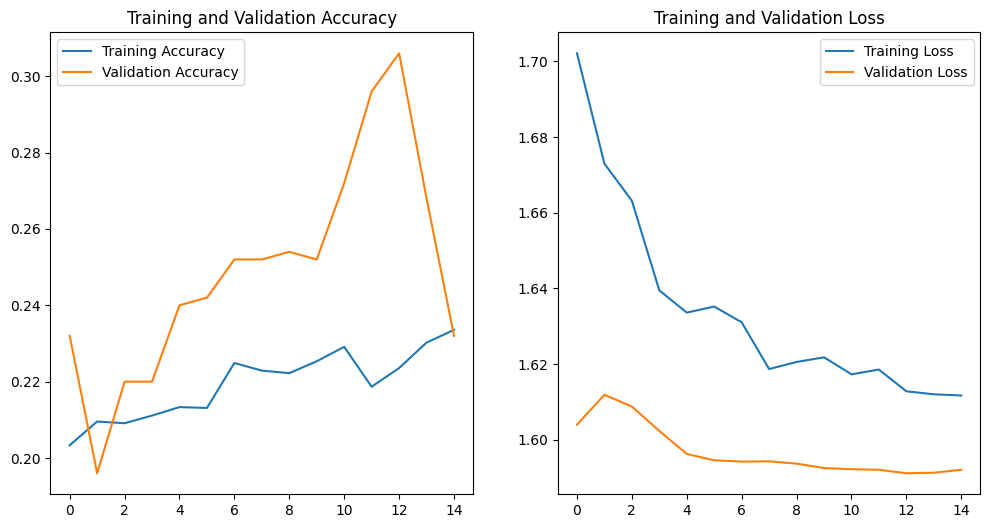

In [21]:
val_accuracy = history_finetune.history['val_accuracy']
val_loss = history_finetune.history['val_loss']
train_accuracy = history_finetune.history['accuracy']
train_loss = history_finetune.history['loss']

epochs = range(len(train_accuracy))

# Plot training  and validation accuracy
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs, train_accuracy, label='Training Accuracy')
plt.plot(epochs, val_accuracy, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(epochs, train_loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 183ms/step


<Figure size 700x600 with 0 Axes>

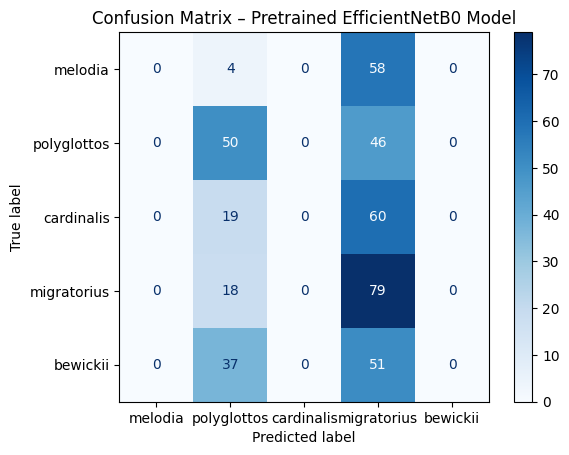

In [22]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

X_test = np.load("./data/processed/X_test.npy")
y_test = np.load("./data/processed/y_test.npy")

y_pred_prob = model.predict(X_test)
y_pred_classes = np.argmax(y_pred_prob, axis=1)

cm = confusion_matrix(y_test, y_pred_classes)

class_names = ["melodia", "polyglottos", "cardinalis", "migratorius", "bewickii"]

plt.figure(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format='d')
plt.title("Confusion Matrix – Pretrained EfficientNetB0 Model")
plt.show()

## 4. Evaluation: Comparing Frozen vs. Lightly Fine-Tuned Models

The performance of both models can be compared using the learning curves and confusion matrices:

**Frozen EfficientNetB0 (no tuning)**

-	Training and validation accuracy remained almost flat at ~0.21–0.23.
-	Confusion matrix shows complete collapse: all samples predicted as a single class.
-	Indicates the pretrained ImageNet features do not transfer to mel-spectrogram data in a frozen state.


**Partially Unfrozen Model (last 30 layers)**

-	Learning curves show modest improvement in validation accuracy (up to ~0.30).
-	Confusion matrix becomes less degenerate, though misclassifications remain dominant.
-	Test accuracy improves from **0.23 -> ~0.31**, confirming that allowing limited feature adaptation helps.


This demonstrates that small amounts of fine-tuning allow EfficientNet to adapt somewhat to audio spectrogram textures, but the improvement remains limited.



## Conclusion

The experiments show that the EfficientNetB0 backbone, even after partial fine-tuning, is not well aligned with the structure of mel-spectrogram inputs. The frozen version fails entirely, and the lightly fine-tuned version achieves only modest improvement.

Although we could continue unfreezing more layers, eventually even the entire backbone, this would make the training process increasingly similar to training a custom CNN from scratch. Since EfficientNet was originally optimized for natural images rather than audio representations, its features remain suboptimal for birdsong classification regardless of the extent of fine-tuning.

A more effective strategy is to adopt a backbone explicitly pretrained on large-scale audio datasets. Models such as YAMNet, PANNs, or HTS-AT are trained to capture time–frequency patterns and generally transfer far better to spectrogram-based tasks. Moving toward such audio-specific architectures is expected to yield substantially better results for this classification problem.

